In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================
# Was ist ein Neuron?
# ============================================
# Ein Neuron macht: output = activation(weights · inputs + bias)

def single_neuron_example():
    """Ein einzelnes Neuron von Hand"""
    
    # Inputs (z.B. Größe und Gewicht einer Person)
    inputs = np.array([1.75, 70])  # [Größe in m, Gewicht in kg]
    
    # Gewichte (werden gelernt!)
    weights = np.array([0.5, 0.3])
    
    # Bias (Offset)
    bias = -0.2
    
    # Schritt 1: Gewichtete Summe
    z = np.dot(weights, inputs) + bias
    print(f"Gewichtete Summe z = {weights[0]}*{inputs[0]} + {weights[1]}*{inputs[1]} + {bias}")
    print(f"z = {z:.4f}")
    
    # Schritt 2: Aktivierungsfunktion (z.B. Sigmoid)
    def sigmoid(x):
        return 1 / (1 + np.exp(-x))
    
    output = sigmoid(z)
    print(f"Output (nach Sigmoid) = {output:.4f}")
    
    return output

# Ausführen
single_neuron_example()

Gewichtete Summe z = 0.5*1.75 + 0.3*70.0 + -0.2
z = 21.6750
Output (nach Sigmoid) = 1.0000


np.float64(0.999999999613929)

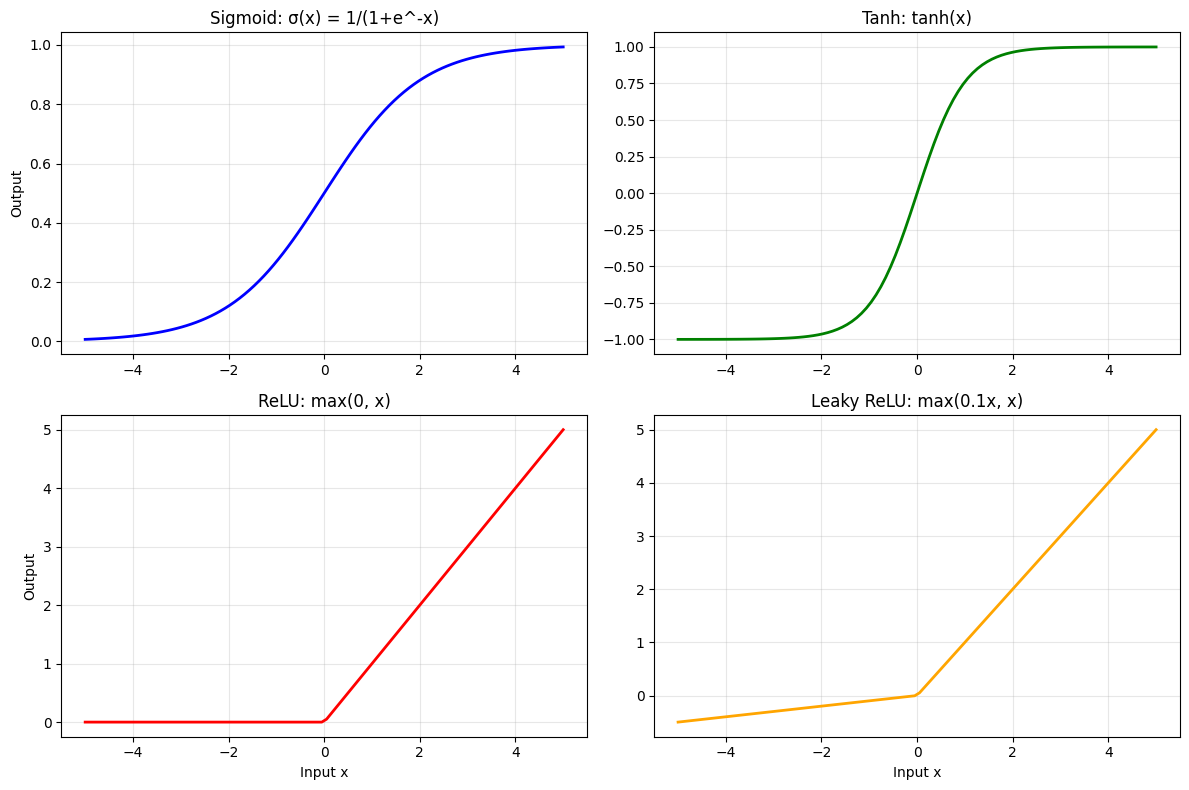

In [2]:
def plot_activation_functions():
    """Zeige verschiedene Aktivierungsfunktionen"""
    
    x = np.linspace(-5, 5, 100)
    
    # Verschiedene Aktivierungsfunktionen
    sigmoid = 1 / (1 + np.exp(-x))
    tanh = np.tanh(x)
    relu = np.maximum(0, x)
    leaky_relu = np.where(x > 0, x, 0.1 * x)
    
    # Plot
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    
    axes[0, 0].plot(x, sigmoid, 'b-', linewidth=2)
    axes[0, 0].set_title('Sigmoid: σ(x) = 1/(1+e^-x)')
    axes[0, 0].grid(True, alpha=0.3)
    axes[0, 0].set_ylabel('Output')
    
    axes[0, 1].plot(x, tanh, 'g-', linewidth=2)
    axes[0, 1].set_title('Tanh: tanh(x)')
    axes[0, 1].grid(True, alpha=0.3)
    
    axes[1, 0].plot(x, relu, 'r-', linewidth=2)
    axes[1, 0].set_title('ReLU: max(0, x)')
    axes[1, 0].grid(True, alpha=0.3)
    axes[1, 0].set_xlabel('Input x')
    axes[1, 0].set_ylabel('Output')
    
    axes[1, 1].plot(x, leaky_relu, 'orange', linewidth=2)
    axes[1, 1].set_title('Leaky ReLU: max(0.1x, x)')
    axes[1, 1].grid(True, alpha=0.3)
    axes[1, 1].set_xlabel('Input x')
    
    plt.tight_layout()
    plt.show()

plot_activation_functions()

=== Training XOR ===
Epoch    0: Loss = 0.267582
Epoch  100: Loss = 0.249232
Epoch  200: Loss = 0.247299
Epoch  300: Loss = 0.240988
Epoch  400: Loss = 0.224571
Epoch  500: Loss = 0.196416
Epoch  600: Loss = 0.166864
Epoch  700: Loss = 0.122630
Epoch  800: Loss = 0.055458
Epoch  900: Loss = 0.019794
Epoch 1000: Loss = 0.008417
Epoch 1100: Loss = 0.004357
Epoch 1200: Loss = 0.002589
Epoch 1300: Loss = 0.001692
Epoch 1400: Loss = 0.001182
Epoch 1500: Loss = 0.000868
Epoch 1600: Loss = 0.000662
Epoch 1700: Loss = 0.000521
Epoch 1800: Loss = 0.000419
Epoch 1900: Loss = 0.000345
Epoch 2000: Loss = 0.000288
Epoch 2100: Loss = 0.000244
Epoch 2200: Loss = 0.000209
Epoch 2300: Loss = 0.000181
Epoch 2400: Loss = 0.000158
Epoch 2500: Loss = 0.000140
Epoch 2600: Loss = 0.000124
Epoch 2700: Loss = 0.000111
Epoch 2800: Loss = 0.000099
Epoch 2900: Loss = 0.000090
Epoch 3000: Loss = 0.000082
Epoch 3100: Loss = 0.000074
Epoch 3200: Loss = 0.000068
Epoch 3300: Loss = 0.000062
Epoch 3400: Loss = 0.000058

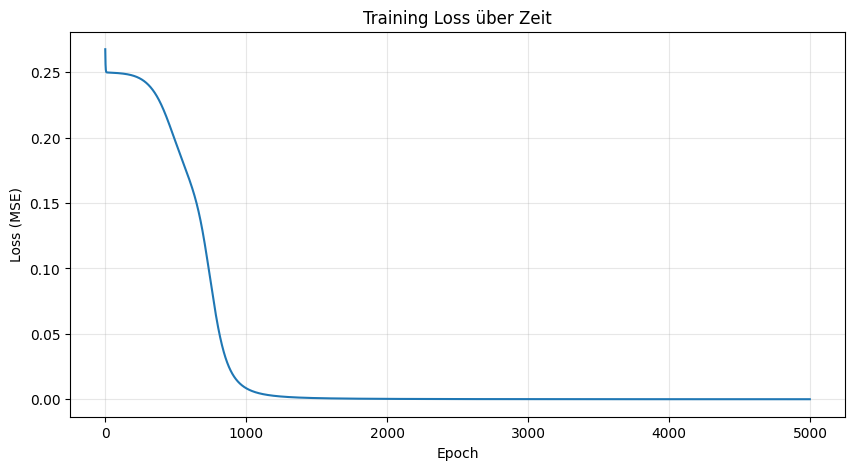

In [3]:
class SimpleNeuralNetwork:
    """
    Ein einfaches 2-Layer Netzwerk von Grund auf
    
    Architektur:
        Input Layer:  2 Neuronen (z.B. x1, x2)
        Hidden Layer: 3 Neuronen
        Output Layer: 1 Neuron
    """
    
    def __init__(self):
        # Initialisiere Gewichte zufällig (klein!)
        np.random.seed(42)
        
        # Input → Hidden (2 inputs, 3 hidden neurons)
        self.W1 = np.random.randn(2, 3) * 0.5
        self.b1 = np.zeros(3)
        
        # Hidden → Output (3 hidden, 1 output)
        self.W2 = np.random.randn(3, 1) * 0.5
        self.b2 = np.zeros(1)
    
    def sigmoid(self, x):
        """Sigmoid Aktivierung"""
        return 1 / (1 + np.exp(-np.clip(x, -500, 500)))  # Clip gegen overflow
    
    def sigmoid_derivative(self, x):
        """Ableitung von Sigmoid (für Backpropagation)"""
        s = self.sigmoid(x)
        return s * (1 - s)
    
    def forward(self, X):
        """
        Forward Pass: Berechne Output
        
        X: Input (n_samples, 2)
        """
        # Layer 1: Input → Hidden
        self.z1 = X @ self.W1 + self.b1  # (n_samples, 3)
        self.a1 = self.sigmoid(self.z1)   # Aktivierung
        
        # Layer 2: Hidden → Output
        self.z2 = self.a1 @ self.W2 + self.b2  # (n_samples, 1)
        self.a2 = self.sigmoid(self.z2)         # Aktivierung
        
        return self.a2
    
    def backward(self, X, y, learning_rate=0.1):
        """
        Backward Pass: Berechne Gradienten und update Gewichte
        
        X: Input (n_samples, 2)
        y: Target (n_samples, 1)
        """
        m = X.shape[0]  # Anzahl Samples
        
        # Output Layer: Fehler
        dz2 = self.a2 - y  # (n_samples, 1)
        dW2 = (self.a1.T @ dz2) / m  # (3, 1)
        db2 = np.sum(dz2, axis=0) / m  # (1,)
        
        # Hidden Layer: Fehler propagieren zurück
        dz1 = (dz2 @ self.W2.T) * self.sigmoid_derivative(self.z1)  # (n_samples, 3)
        dW1 = (X.T @ dz1) / m  # (2, 3)
        db1 = np.sum(dz1, axis=0) / m  # (3,)
        
        # Update Gewichte (Gradient Descent)
        self.W2 -= learning_rate * dW2
        self.b2 -= learning_rate * db2
        self.W1 -= learning_rate * dW1
        self.b1 -= learning_rate * db1
    
    def train(self, X, y, epochs=1000, learning_rate=0.1, verbose=True):
        """
        Trainiere das Netzwerk
        """
        losses = []
        
        for epoch in range(epochs):
            # Forward Pass
            output = self.forward(X)
            
            # Loss berechnen (Mean Squared Error)
            loss = np.mean((output - y) ** 2)
            losses.append(loss)
            
            # Backward Pass
            self.backward(X, y, learning_rate)
            
            # Ausgabe alle 100 Epochen
            if verbose and epoch % 100 == 0:
                print(f"Epoch {epoch:4d}: Loss = {loss:.6f}")
        
        return losses
    
    def predict(self, X):
        """Vorhersage"""
        return self.forward(X)

# ============================================
# Beispiel: XOR Problem
# ============================================
# XOR ist nicht linear trennbar → braucht Hidden Layer!

# Daten
X_train = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y_train = np.array([
    [0],  # 0 XOR 0 = 0
    [1],  # 0 XOR 1 = 1
    [1],  # 1 XOR 0 = 1
    [0]   # 1 XOR 1 = 0
])

# Netzwerk erstellen und trainieren
nn = SimpleNeuralNetwork()
print("=== Training XOR ===")
losses = nn.train(X_train, y_train, epochs=5000, learning_rate=0.5)

# Vorhersagen
print("\n=== Vorhersagen ===")
predictions = nn.predict(X_train)
for i in range(len(X_train)):
    print(f"Input: {X_train[i]} → Prediction: {predictions[i][0]:.4f} (Target: {y_train[i][0]})")

# Loss Plot
plt.figure(figsize=(10, 5))
plt.plot(losses)
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.title('Training Loss über Zeit')
plt.grid(True, alpha=0.3)
plt.show()

In [5]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# ============================================
# Beispiel: Gedämpfte Schwingungen als DataFrame
# ============================================

def generate_oscillation_dataset(n_oscillations=20):
    """
    Generiere Dataset mit gedämpften Schwingungen
    """
    from scipy.stats import qmc
    
    # Latin Hypercube Sampling für gute Abdeckung
    sampler = qmc.LatinHypercube(d=4, seed=42)
    samples = sampler.random(n=n_oscillations)
    
    all_data = []
    
    for i, sample in enumerate(samples):
        # Parameter
        A = 0.5 + sample[0] * 1.5
        alpha = 0.01 + sample[1] * 0.14
        omega = (1.0 + sample[2] * 3.0) * np.pi
        phi = sample[3] * 2 * np.pi
        
        # Zeitreihe
        t = np.linspace(0, 10, 1000)
        y = A * np.exp(-alpha * t) * np.sin(omega * t + phi)
        
        # Als DataFrame (jeder Zeitschritt = eine Zeile)
        for j in range(len(t) - 1):
            all_data.append({
                'oscillation_id': i,
                'time': t[j],
                'y_current': y[j],
                'y_next': y[j + 1],  # Das wollen wir vorhersagen!
                'A': A,
                'alpha': alpha,
                'omega': omega,
                'phi': phi
            })
    
    df = pd.DataFrame(all_data)
    return df

# Dataset generieren
df = generate_oscillation_dataset(n_oscillations=20)

print("=== Dataset Info ===")
print(df.info())
print("\n=== Erste Zeilen ===")
print(df.head(10))
print("\n=== Statistiken ===")
print(df.describe())

# ============================================
# Daten vorbereiten für ML
# ============================================

# Features (X) und Target (y)
X = df[['y_current']].values  # Nur aktueller Wert
y = df[['y_next']].values     # Nächster Wert

# Train/Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Normalisierung (wichtig für NN!)
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)
y_train_scaled = scaler_y.fit_transform(y_train)
y_test_scaled = scaler_y.transform(y_test)

print(f"\n=== Daten Shapes ===")
print(f"X_train: {X_train_scaled.shape}")
print(f"X_test:  {X_test_scaled.shape}")
print(f"y_train: {y_train_scaled.shape}")
print(f"y_test:  {y_test_scaled.shape}")

=== Dataset Info ===
<class 'pandas.DataFrame'>
RangeIndex: 19980 entries, 0 to 19979
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   oscillation_id  19980 non-null  int64  
 1   time            19980 non-null  float64
 2   y_current       19980 non-null  float64
 3   y_next          19980 non-null  float64
 4   A               19980 non-null  float64
 5   alpha           19980 non-null  float64
 6   omega           19980 non-null  float64
 7   phi             19980 non-null  float64
dtypes: float64(7), int64(1)
memory usage: 1.2 MB
None

=== Erste Zeilen ===
   oscillation_id     time  y_current    y_next         A     alpha    omega  \
0               0  0.00000   1.335893  1.324928  1.341953  0.062928  6.03566   
1               0  0.01001   1.324928  1.309146  1.341953  0.062928  6.03566   
2               0  0.02002   1.309146  1.288608  1.341953  0.062928  6.03566   
3               0  0.03003   1.2886

=== Lineare Regression ===
MSE: 0.006839
R²:  0.993027

=== Ridge Regression ===
MSE: 0.006839
R²:  0.993027

=== Random Forest ===
MSE: 0.010069
R²:  0.989733


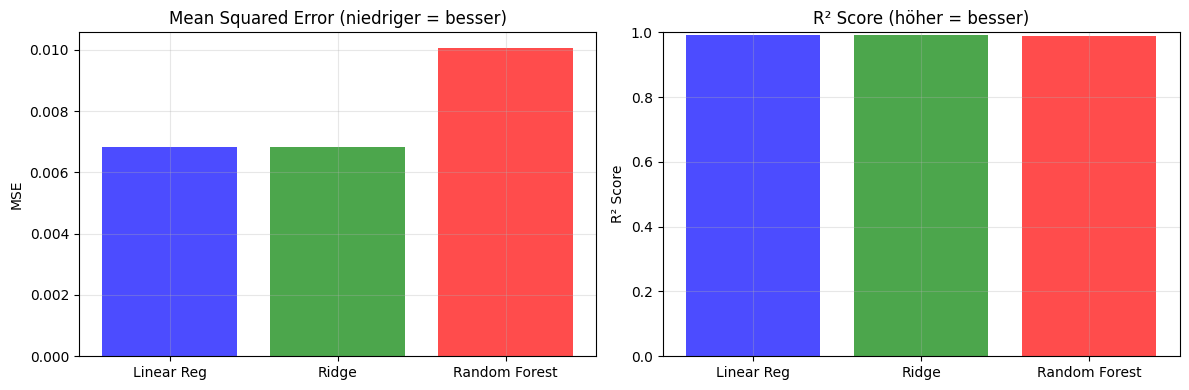

In [6]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# ============================================
# 1. Lineare Regression (einfachste Baseline)
# ============================================

lr = LinearRegression()
lr.fit(X_train_scaled, y_train_scaled)
y_pred_lr = lr.predict(X_test_scaled)

mse_lr = mean_squared_error(y_test_scaled, y_pred_lr)
r2_lr = r2_score(y_test_scaled, y_pred_lr)

print("=== Lineare Regression ===")
print(f"MSE: {mse_lr:.6f}")
print(f"R²:  {r2_lr:.6f}")

# ============================================
# 2. Ridge Regression (mit Regularisierung)
# ============================================

ridge = Ridge(alpha=1.0)
ridge.fit(X_train_scaled, y_train_scaled)
y_pred_ridge = ridge.predict(X_test_scaled)

mse_ridge = mean_squared_error(y_test_scaled, y_pred_ridge)
r2_ridge = r2_score(y_test_scaled, y_pred_ridge)

print("\n=== Ridge Regression ===")
print(f"MSE: {mse_ridge:.6f}")
print(f"R²:  {r2_ridge:.6f}")

# ============================================
# 3. Random Forest (komplexeres Modell)
# ============================================

rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train_scaled, y_train_scaled.ravel())
y_pred_rf = rf.predict(X_test_scaled)

mse_rf = mean_squared_error(y_test_scaled, y_pred_rf)
r2_rf = r2_score(y_test_scaled, y_pred_rf)

print("\n=== Random Forest ===")
print(f"MSE: {mse_rf:.6f}")
print(f"R²:  {r2_rf:.6f}")

# ============================================
# Vergleich visualisieren
# ============================================

models = ['Linear Reg', 'Ridge', 'Random Forest']
mses = [mse_lr, mse_ridge, mse_rf]
r2s = [r2_lr, r2_ridge, r2_rf]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(models, mses, color=['blue', 'green', 'red'], alpha=0.7)
axes[0].set_ylabel('MSE')
axes[0].set_title('Mean Squared Error (niedriger = besser)')
axes[0].grid(True, alpha=0.3)

axes[1].bar(models, r2s, color=['blue', 'green', 'red'], alpha=0.7)
axes[1].set_ylabel('R² Score')
axes[1].set_title('R² Score (höher = besser)')
axes[1].grid(True, alpha=0.3)
axes[1].set_ylim([0, 1])

plt.tight_layout()
plt.show()

=== Dataset Sizes ===
Train: 15984 samples
Test:  3996 samples

=== Model Architektur ===
SimpleMLP(
  (fc1): Linear(in_features=1, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=32, bias=True)
  (fc3): Linear(in_features=32, out_features=1, bias=True)
  (relu): ReLU()
)

Total Parameters: 2241

=== Training ===
Epoch  10: Train Loss = 0.007066, Test Loss = 0.007402
Epoch  20: Train Loss = 0.007027, Test Loss = 0.006991
Epoch  30: Train Loss = 0.006984, Test Loss = 0.007009
Epoch  40: Train Loss = 0.006959, Test Loss = 0.006923
Epoch  50: Train Loss = 0.006953, Test Loss = 0.006860


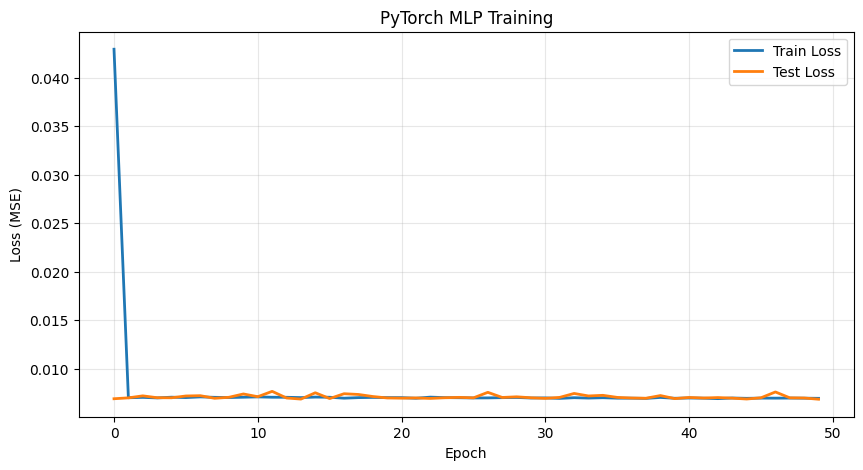

In [7]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

# ============================================
# 4.1 Custom Dataset
# ============================================

class OscillationDataset(Dataset):
    """
    Custom PyTorch Dataset für gedämpfte Schwingungen
    """
    
    def __init__(self, X, y):
        # Konvertiere zu PyTorch Tensors
        self.X = torch.FloatTensor(X)
        self.y = torch.FloatTensor(y)
    
    def __len__(self):
        return len(self.X)
    
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# Datasets erstellen
train_dataset = OscillationDataset(X_train_scaled, y_train_scaled)
test_dataset = OscillationDataset(X_test_scaled, y_test_scaled)

# DataLoaders (für Batch-Training)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print(f"=== Dataset Sizes ===")
print(f"Train: {len(train_dataset)} samples")
print(f"Test:  {len(test_dataset)} samples")

# ============================================
# 4.2 Einfaches Feedforward Netzwerk
# ============================================

class SimpleMLP(nn.Module):
    """
    Multi-Layer Perceptron (MLP)
    
    Architektur:
        Input → Hidden1 (64) → Hidden2 (32) → Output
    """
    
    def __init__(self, input_size=1, hidden1=64, hidden2=32, output_size=1):
        super(SimpleMLP, self).__init__()
        
        # Layers definieren
        self.fc1 = nn.Linear(input_size, hidden1)
        self.fc2 = nn.Linear(hidden1, hidden2)
        self.fc3 = nn.Linear(hidden2, output_size)
        
        # Aktivierungsfunktion
        self.relu = nn.ReLU()
    
    def forward(self, x):
        """
        Forward Pass
        
        x: Input (batch_size, input_size)
        """
        # Layer 1
        x = self.fc1(x)
        x = self.relu(x)
        
        # Layer 2
        x = self.fc2(x)
        x = self.relu(x)
        
        # Output Layer (keine Aktivierung für Regression!)
        x = self.fc3(x)
        
        return x

# Model erstellen
model = SimpleMLP(input_size=1, hidden1=64, hidden2=32, output_size=1)

print("\n=== Model Architektur ===")
print(model)

# Anzahl Parameter
total_params = sum(p.numel() for p in model.parameters())
print(f"\nTotal Parameters: {total_params}")

# ============================================
# 4.3 Training Loop (manuell)
# ============================================

# Loss Function und Optimizer
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Training
epochs = 50
train_losses = []
test_losses = []

print("\n=== Training ===")
for epoch in range(epochs):
    # Training Mode
    model.train()
    train_loss = 0.0
    
    for X_batch, y_batch in train_loader:
        # Forward Pass
        y_pred = model(X_batch)
        loss = criterion(y_pred, y_batch)
        
        # Backward Pass
        optimizer.zero_grad()  # Gradienten zurücksetzen
        loss.backward()        # Gradienten berechnen
        optimizer.step()       # Gewichte updaten
        
        train_loss += loss.item()
    
    train_loss /= len(train_loader)
    train_losses.append(train_loss)
    
    # Evaluation Mode
    model.eval()
    test_loss = 0.0
    
    with torch.no_grad():  # Keine Gradienten berechnen
        for X_batch, y_batch in test_loader:
            y_pred = model(X_batch)
            loss = criterion(y_pred, y_batch)
            test_loss += loss.item()
    
    test_loss /= len(test_loader)
    test_losses.append(test_loss)
    
    # Ausgabe
    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1:3d}: Train Loss = {train_loss:.6f}, Test Loss = {test_loss:.6f}")

# Plot Training Curve
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='Train Loss', linewidth=2)
plt.plot(test_losses, label='Test Loss', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.title('PyTorch MLP Training')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [8]:
import pytorch_lightning as pl
from torchmetrics import MeanSquaredError, R2Score

class LitMLP(pl.LightningModule):
    """
    PyTorch Lightning Wrapper für MLP
    
    Vorteile:
    - Automatisches Training/Validation/Test
    - Logging
    - Checkpointing
    - Multi-GPU Support
    """
    
    def __init__(self, input_size=1, hidden1=64, hidden2=32, output_size=1, lr=0.001):
        super().__init__()
        
        # Hyperparameter speichern
        self.save_hyperparameters()
        
        # Model
        self.model = SimpleMLP(input_size, hidden1, hidden2, output_size)
        
        # Loss
        self.criterion = nn.MSELoss()
        
        # Metriken
        self.train_mse = MeanSquaredError()
        self.val_mse = MeanSquaredError()
        self.test_mse = MeanSquaredError()
        self.test_r2 = R2Score()
    
    def forward(self, x):
        return self.model(x)
    
    def training_step(self, batch, batch_idx):
        """Training Step (wird automatisch aufgerufen)"""
        x, y = batch
        y_pred = self(x)
        loss = self.criterion(y_pred, y)
        
        # Logging
        self.log('train_loss', loss, prog_bar=True)
        self.train_mse(y_pred, y)
        self.log('train_mse', self.train_mse, prog_bar=True)
        
        return loss
    
    def validation_step(self, batch, batch_idx):
        """Validation Step"""
        x, y = batch
        y_pred = self(x)
        loss = self.criterion(y_pred, y)
        
        # Logging
        self.log('val_loss', loss, prog_bar=True)
        self.val_mse(y_pred, y)
        self.log('val_mse', self.val_mse, prog_bar=True)
        
        return loss
    
    def test_step(self, batch, batch_idx):
        """Test Step"""
        x, y = batch
        y_pred = self(x)
        
        # Metriken
        self.test_mse(y_pred, y)
        self.test_r2(y_pred, y)
        
        self.log('test_mse', self.test_mse)
        self.log('test_r2', self.test_r2)
    
    def configure_optimizers(self):
        """Optimizer konfigurieren"""
        return optim.Adam(self.parameters(), lr=self.hparams.lr)

# ============================================
# Training mit PyTorch Lightning
# ============================================

# Model
lit_model = LitMLP(input_size=1, hidden1=64, hidden2=32, lr=0.001)

# Trainer
trainer = pl.Trainer(
    max_epochs=50,
    accelerator='auto',  # Automatisch GPU/CPU
    log_every_n_steps=10,
    enable_progress_bar=True,
    enable_checkpointing=False  # Für Demo ausgeschaltet
)

# Training
print("\n=== PyTorch Lightning Training ===")
trainer.fit(lit_model, train_loader, test_loader)

# Testing
print("\n=== Testing ===")
trainer.test(lit_model, test_loader)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
c:\Users\ilija\Documents\OST\Semester_6\ANN\Projekt\applied_neural_networks_fs25\.venv\Lib\site-packages\pytorch_lightning\trainer\connectors\logger_connector\logger_connector.py:76: Starting from v1.9.0, `tensorboardX` has been removed as a dependency of the `pytorch_lightning` package, due to potential conflicts with other packages in the ML ecosystem. For this reason, `logger=True` will use `CSVLogger` as the default logger, unless the `tensorboard` or `tensorboardX` packages are found. Please `pip install lightning[extra]` or one of them to enable TensorBoard support by default
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.

  | Name      | Type             | Params | Mode  | FLOPs
-----------------------------------------------


=== PyTorch Lightning Training ===
                                                                           

c:\Users\ilija\Documents\OST\Semester_6\ANN\Projekt\applied_neural_networks_fs25\.venv\Lib\site-packages\pytorch_lightning\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
c:\Users\ilija\Documents\OST\Semester_6\ANN\Projekt\applied_neural_networks_fs25\.venv\Lib\site-packages\pytorch_lightning\trainer\connectors\data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=13` in the `DataLoader` to improve performance.
c:\Users\ilija\Documents\OST\Semester_6\ANN\Projekt\applied_neural_networks_fs25\.venv\Lib\site-packages\pytorch_lightning\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=13` in the `DataLoader` to improve performance.


Epoch 49: 100%|██████████| 500/500 [00:05<00:00, 94.22it/s, v_num=0, train_loss=0.00775, train_mse=0.00775, val_loss=0.00688, val_mse=0.00688] 

`Trainer.fit` stopped: `max_epochs=50` reached.


Epoch 49: 100%|██████████| 500/500 [00:05<00:00, 94.20it/s, v_num=0, train_loss=0.00775, train_mse=0.00775, val_loss=0.00688, val_mse=0.00688]

=== Testing ===


c:\Users\ilija\Documents\OST\Semester_6\ANN\Projekt\applied_neural_networks_fs25\.venv\Lib\site-packages\pytorch_lightning\trainer\connectors\data_connector.py:434: The 'test_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=13` in the `DataLoader` to improve performance.


Testing DataLoader 0: 100%|██████████| 125/125 [00:00<00:00, 270.08it/s]
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
       Test metric             DataLoader 0
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
        test_mse           0.006880701519548893
         test_r2             0.992984414100647
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────


[{'test_mse': 0.006880701519548893, 'test_r2': 0.992984414100647}]

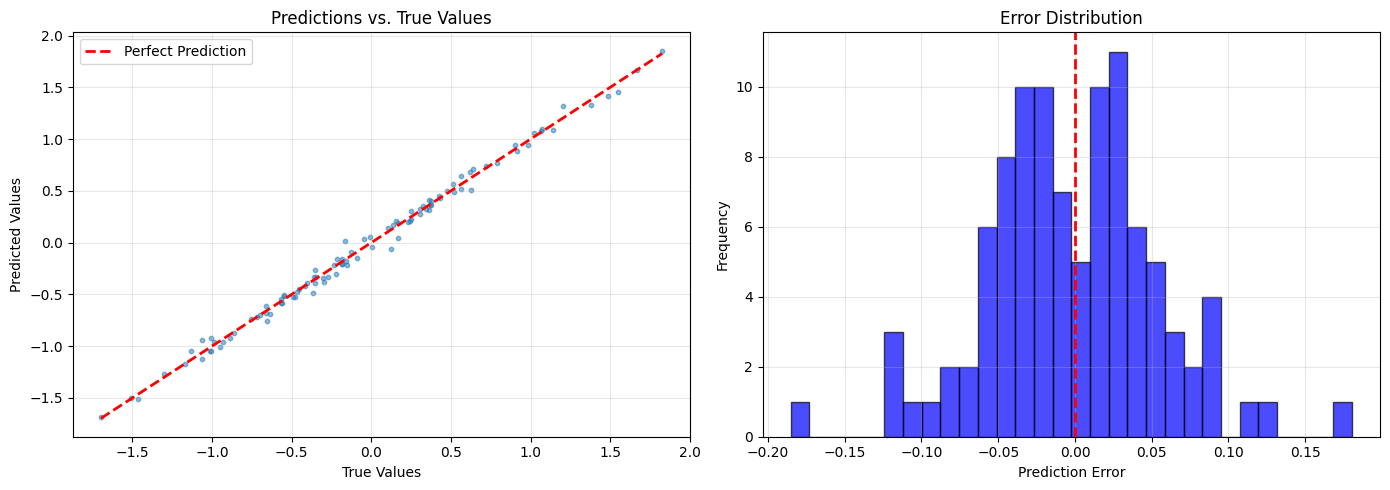

=== Prediction Statistics ===
Mean Error: -0.002448
Std Error:  0.056258
MAE:        0.044031
RMSE:       0.056311


In [9]:
import seaborn as sns

# ============================================
# Vorhersagen visualisieren
# ============================================

def plot_predictions(model, test_loader, scaler_y, n_samples=100):
    """
    Zeige Vorhersagen vs. Ground Truth
    """
    model.eval()
    
    y_true_all = []
    y_pred_all = []
    
    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            y_pred = model(X_batch)
            y_true_all.append(y_batch.numpy())
            y_pred_all.append(y_pred.numpy())
    
    y_true = np.concatenate(y_true_all)[:n_samples]
    y_pred = np.concatenate(y_pred_all)[:n_samples]
    
    # Zurück-transformieren
    y_true_orig = scaler_y.inverse_transform(y_true)
    y_pred_orig = scaler_y.inverse_transform(y_pred)
    
    # Plot
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Scatter Plot
    axes[0].scatter(y_true_orig, y_pred_orig, alpha=0.5, s=10)
    axes[0].plot([y_true_orig.min(), y_true_orig.max()], 
                 [y_true_orig.min(), y_true_orig.max()], 
                 'r--', linewidth=2, label='Perfect Prediction')
    axes[0].set_xlabel('True Values')
    axes[0].set_ylabel('Predicted Values')
    axes[0].set_title('Predictions vs. True Values')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    # Error Distribution
    errors = y_pred_orig - y_true_orig
    axes[1].hist(errors, bins=30, alpha=0.7, color='blue', edgecolor='black')
    axes[1].set_xlabel('Prediction Error')
    axes[1].set_ylabel('Frequency')
    axes[1].set_title('Error Distribution')
    axes[1].axvline(0, color='r', linestyle='--', linewidth=2)
    axes[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # Statistiken
    print("=== Prediction Statistics ===")
    print(f"Mean Error: {np.mean(errors):.6f}")
    print(f"Std Error:  {np.std(errors):.6f}")
    print(f"MAE:        {np.mean(np.abs(errors)):.6f}")
    print(f"RMSE:       {np.sqrt(np.mean(errors**2)):.6f}")

# Ausführen
plot_predictions(lit_model.model, test_loader, scaler_y)

# ============================================
# Confusion Matrix für Klassifikation (Bonus)
# ============================================
# Falls du später Klassifikation machst:

def plot_confusion_matrix_example():
    """Beispiel für Klassifikation"""
    from sklearn.metrics import confusion_matrix
    
    # Dummy Daten
    y_true = np.array([0, 1, 2, 0, 1, 2, 0, 1, 2, 0])
    y_pred = np.array([0, 2, 2, 0, 1, 1, 0, 1, 2, 0])
    
    cm = confusion_matrix(y_true, y_pred)
    
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.title('Confusion Matrix')
    plt.show()

# plot_confusion_matrix_example()  # Uncomment zum Anzeigen

In [ ]:
# ============================================
# CHEAT SHEET: Neuronale Netze
# ============================================

"""
1. GRUNDSTRUKTUR:
   Input → Hidden Layers → Output

2. FORWARD PASS:
   z = W·x + b        (Lineare Transformation)
   a = σ(z)           (Aktivierung)

3. LOSS BERECHNEN:
   L = (y_true - y_pred)²  (für Regression)
   
4. BACKWARD PASS (Backpropagation):
   ∂L/∂W → Gradienten berechnen
   
5. GEWICHTE UPDATEN:
   W_neu = W_alt - lr · ∂L/∂W

6. WICHTIGE KOMPONENTEN:
   - Activation Functions: ReLU, Sigmoid, Tanh
   - Loss Functions: MSE, CrossEntropy
   - Optimizers: SGD, Adam, RMSprop
   - Regularization: Dropout, L2

7. PYTORCH WORKFLOW:
   a) Dataset erstellen (torch.utils.data.Dataset)
   b) DataLoader für Batches
   c) Model definieren (nn.Module)
   d) Loss & Optimizer wählen
   e) Training Loop
   f) Evaluation
"""

print("""
=== NÄCHSTE SCHRITTE ===

Für dein Reservoir Computing Projekt:

1. ✅ Daten generieren (gedämpfte Schwingungen mit LHS)
2. ✅ Baseline erstellen (Linear Regression, Random Forest)
3. 🔄 ESN implementieren (mit NumPy oder PyTorch)
4. 🔄 LSTM implementieren (mit PyTorch)
5. 🔄 Beide vergleichen (MSE, Training Zeit, etc.)

Möchtest du, dass ich dir jetzt den kompletten Code für 
ESN vs. LSTM Vergleich schreibe?
""")